# Explainable AI

In [1]:
import shap
import matplotlib.pyplot as plt
from scipy import sparse

In [5]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

PROJECT_ROOT = Path.cwd()
MODEL_PATH = PROJECT_ROOT / "models" / "tuned_xgboost.pkl"
PREPROCESSOR_PATH = PROJECT_ROOT / "models" / "preprocessor.pkl"
DATA_PATH = PROJECT_ROOT / "Dataset" / "churn_data.csv"

for path in [MODEL_PATH, PREPROCESSOR_PATH, DATA_PATH]:
    print(path, "exists:", path.exists())

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Update MODEL_PATH: {MODEL_PATH}")
if not PREPROCESSOR_PATH.exists():
    raise FileNotFoundError(f"Update PREPROCESSOR_PATH: {PREPROCESSOR_PATH}")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Update DATA_PATH to your churn data CSV: {DATA_PATH}")

model = joblib.load(MODEL_PATH)
preprocessor = joblib.load(PREPROCESSOR_PATH)
processed_df = pd.read_csv(DATA_PATH)

print("Model:", type(model).__name__)
print("Preprocessor:", type(preprocessor).__name__)
print("Processed data shape:", processed_df.shape)
display(processed_df.head())

c:\Users\ASUS\Documents\GIT_FOLDERS\ChurnIQ\models\tuned_xgboost.pkl exists: True
c:\Users\ASUS\Documents\GIT_FOLDERS\ChurnIQ\models\preprocessor.pkl exists: True
c:\Users\ASUS\Documents\GIT_FOLDERS\ChurnIQ\Dataset\churn_data.csv exists: True
Model: XGBClassifier
Preprocessor: ColumnTransformer
Processed data shape: (7032, 21)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,1 - 12
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,25 - 36
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1 - 12
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,37 - 48
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1 - 12


In [8]:
# Use the exact raw columns the saved preprocessor was fitted on.
if not hasattr(preprocessor, "feature_names_in_"):
    raise ValueError("Preprocessor has no feature_names_in_. Define feature_columns manually to match training.")

feature_columns = list(preprocessor.feature_names_in_)
missing = [c for c in feature_columns if c not in processed_df.columns]
if missing:
    raise ValueError(
        f"Missing raw columns: {missing}. Use the same schema as training; "
        "if training used tenure_group, the CSV must contain tenure_group."
    )

X_raw = processed_df.loc[:, feature_columns].copy()
print("Feature columns:", feature_columns)
display(X_raw.head())

Feature columns: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'tenure_group']


,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,tenure_group
0,Female,No,Yes,No,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,1 - 12
1,Male,No,No,No,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,25 - 36
2,Male,No,No,No,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1 - 12
3,Male,No,No,No,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,37 - 48
4,Female,No,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1 - 12


In [9]:
# Transform using the fitted preprocessor only; do not fit it again.
Xt = preprocessor.transform(X_raw)
if hasattr(Xt, "toarray"):
    Xt = Xt.toarray()
else:
    Xt = np.asarray(Xt)

if Xt.ndim != 2 or not np.issubdtype(Xt.dtype, np.number):
    raise TypeError(f"Expected a 2D numeric transformed matrix; shape={Xt.shape}, dtype={Xt.dtype}")

expected = getattr(model, "n_features_in_", Xt.shape[1])
if Xt.shape[1] != expected:
    raise ValueError(f"Feature mismatch: preprocessor outputs {Xt.shape[1]}, model expects {expected}.")

try:
    names = list(preprocessor.get_feature_names_out())
except Exception:
    names = [f"feature_{i}" for i in range(Xt.shape[1])]
if len(names) != Xt.shape[1]:
    names = [f"feature_{i}" for i in range(Xt.shape[1])]

X_transformed = pd.DataFrame(Xt, columns=names)
sample_size = min(300, len(X_transformed))
X_sample = X_transformed.sample(n=sample_size, random_state=42).reset_index(drop=True)
print("Transformed sample:", X_sample.shape)
display(X_sample.head())

Transformed sample: (300, 51)


,num__MonthlyCharges,num__TotalCharges,cat__gender_Female,cat__gender_Male,cat__SeniorCitizen_No,cat__SeniorCitizen_Yes,cat__Partner_No,cat__Partner_Yes,cat__Dependents_No,cat__Dependents_Yes,...,cat__PaymentMethod_Bank transfer (automatic),cat__PaymentMethod_Credit card (automatic),cat__PaymentMethod_Electronic check,cat__PaymentMethod_Mailed check,cat__tenure_group_1 - 12,cat__tenure_group_13 - 24,cat__tenure_group_25 - 36,cat__tenure_group_37 - 48,cat__tenure_group_49 - 60,cat__tenure_group_61 - 72
0,-1.328618,-0.351628,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,-1.338582,-0.806892,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,1.237319,-0.414365,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,-0.330477,-0.119140,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
4,-1.180806,-0.940672,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [10]:
# TreeExplainer is suitable for XGBoost tree models.
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_sample)
print("SHAP values shape:", np.asarray(shap_values.values).shape)

SHAP values shape: (300, 51)


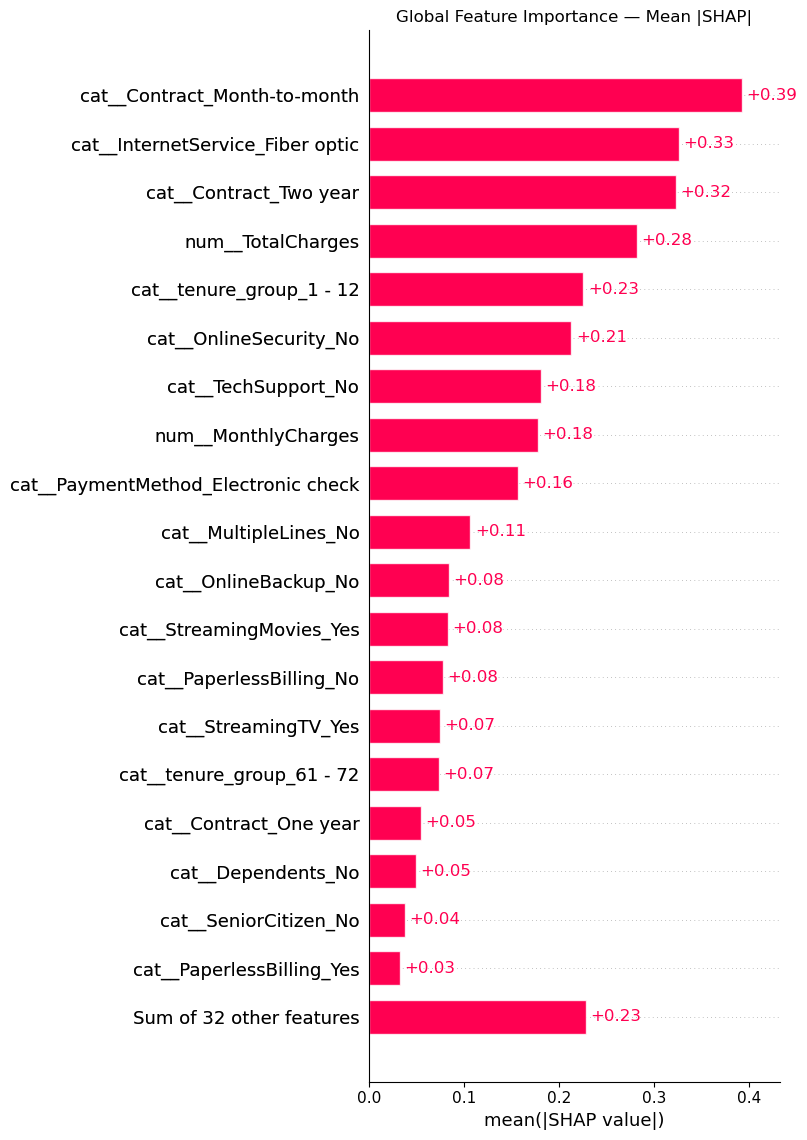

,feature,mean_abs_shap
0,cat__Contract_Month-to-month,0.391916
1,cat__InternetService_Fiber optic,0.325908
2,cat__Contract_Two year,0.322804
3,num__TotalCharges,0.281875
4,cat__tenure_group_1 - 12,0.225321
5,cat__OnlineSecurity_No,0.212792
6,cat__TechSupport_No,0.180659
7,num__MonthlyCharges,0.177740
8,cat__PaymentMethod_Electronic check,0.156076
9,cat__MultipleLines_No,0.106550


In [11]:
# Global importance: mean absolute SHAP value.
shap.plots.bar(shap_values, max_display=20, show=False)
plt.title("Global Feature Importance — Mean |SHAP|")
plt.tight_layout()
plt.show()

mean_abs = np.abs(np.asarray(shap_values.values)).mean(axis=0)
global_importance = pd.DataFrame({
    "feature": X_sample.columns,
    "mean_abs_shap": mean_abs
}).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
display(global_importance.head(20))

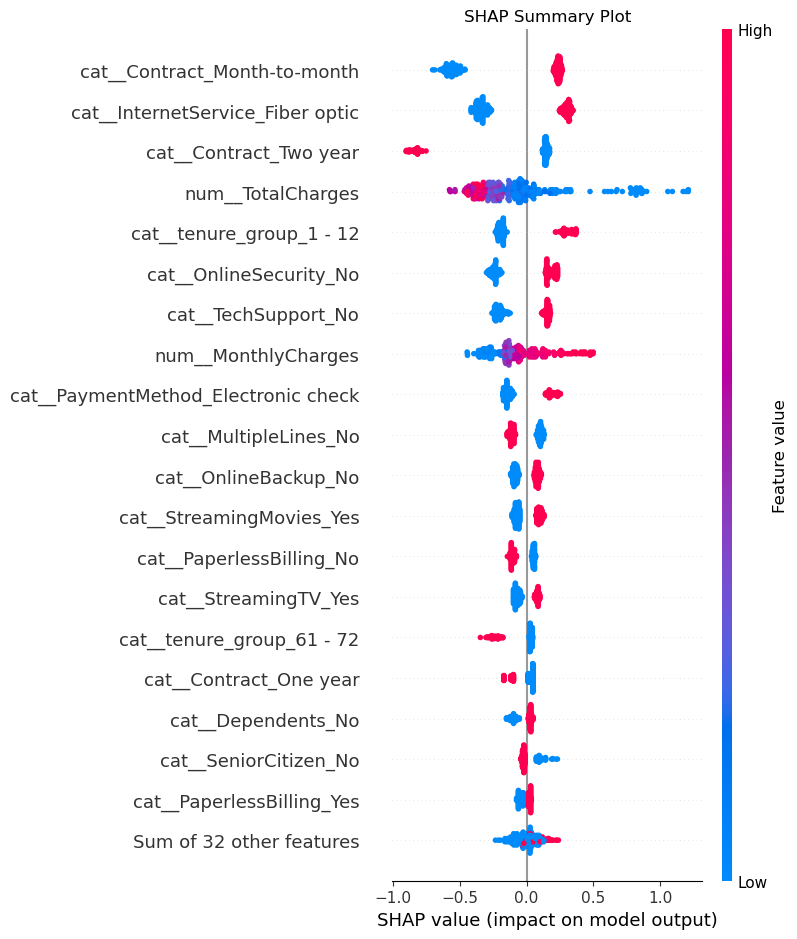

In [12]:
# Beeswarm: direction and distribution of feature contributions.
shap.plots.beeswarm(shap_values, max_display=20, show=False)
plt.title("SHAP Summary Plot")
plt.tight_layout()
plt.show()

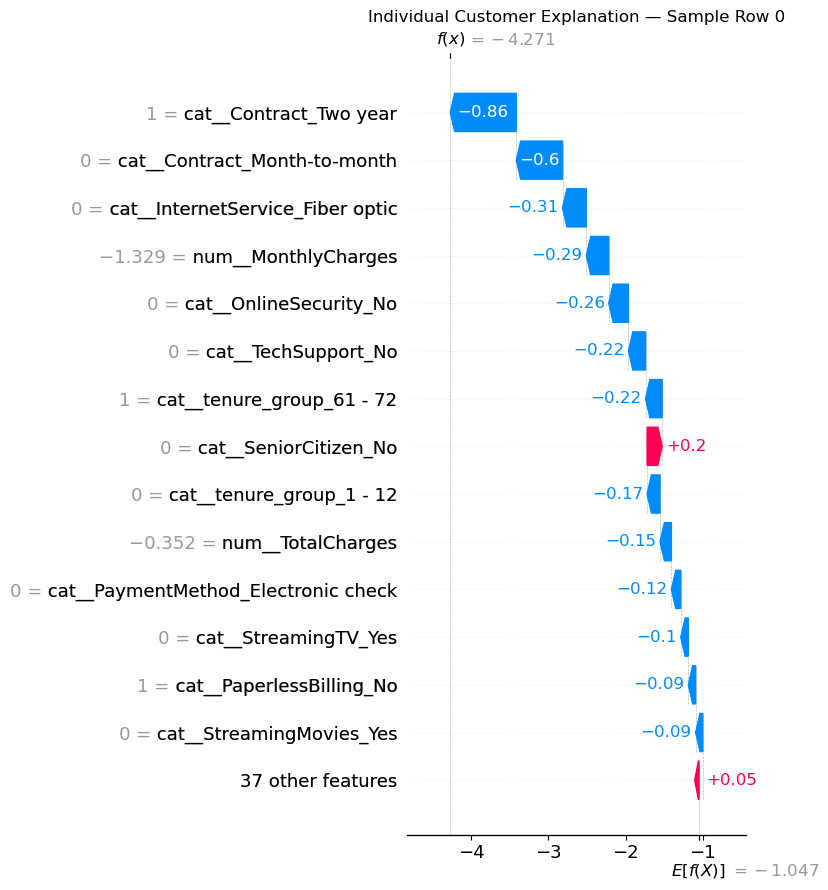

,num__MonthlyCharges,num__TotalCharges,cat__gender_Female,cat__gender_Male,cat__SeniorCitizen_No,cat__SeniorCitizen_Yes,cat__Partner_No,cat__Partner_Yes,cat__Dependents_No,cat__Dependents_Yes,...,cat__PaymentMethod_Bank transfer (automatic),cat__PaymentMethod_Credit card (automatic),cat__PaymentMethod_Electronic check,cat__PaymentMethod_Mailed check,cat__tenure_group_1 - 12,cat__tenure_group_13 - 24,cat__tenure_group_25 - 36,cat__tenure_group_37 - 48,cat__tenure_group_49 - 60,cat__tenure_group_61 - 72
0,-1.328618,-0.351628,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [13]:
# Explain one example row. Change row_index to inspect another customer.
row_index = 0
if not 0 <= row_index < len(X_sample):
    raise IndexError(f"row_index must be between 0 and {len(X_sample)-1}")

shap.plots.waterfall(shap_values[row_index], max_display=15, show=False)
plt.title(f"Individual Customer Explanation — Sample Row {row_index}")
plt.tight_layout()
plt.show()

display(X_sample.iloc[[row_index]])

In [14]:
# List the largest contributions for this individual prediction.
local_values = np.asarray(shap_values.values[row_index]).reshape(-1)
local_explanation = pd.DataFrame({
    "feature": X_sample.columns,
    "transformed_value": X_sample.iloc[row_index].to_numpy(),
    "shap_value": local_values,
    "absolute_shap": np.abs(local_values)
}).sort_values("absolute_shap", ascending=False)
display(local_explanation.head(15))

,feature,transformed_value,shap_value,absolute_shap
38,cat__Contract_Two year,1.000000,-0.855776,0.855776
36,cat__Contract_Month-to-month,0.000000,-0.598558,0.598558
16,cat__InternetService_Fiber optic,0.000000,-0.308774,0.308774
0,num__MonthlyCharges,-1.328618,-0.290483,0.290483
18,cat__OnlineSecurity_No,0.000000,-0.255245,0.255245
27,cat__TechSupport_No,0.000000,-0.221477,0.221477
50,cat__tenure_group_61 - 72,1.000000,-0.215382,0.215382
4,cat__SeniorCitizen_No,0.000000,0.195643,0.195643
45,cat__tenure_group_1 - 12,0.000000,-0.168014,0.168014
1,num__TotalCharges,-0.351628,-0.147445,0.147445


In [15]:
# Optional: model probability for the same row (not the same as SHAP contribution).
classes = getattr(model, "classes_", None)
positive_idx = None
if classes is not None:
    for i, cls in enumerate(classes):
        if str(cls).strip().lower() in {"1", "yes", "true", "churn"}:
            positive_idx = i
            break

if hasattr(model, "predict_proba"):
    probs = model.predict_proba(X_sample.iloc[[row_index]])[0]
    if positive_idx is None:
        positive_idx = 1 if len(probs) > 1 else 0
    print(f"Predicted positive/churn probability: {probs[positive_idx]:.1%}")
    print("Model classes:", classes)
else:
    print("Model does not support predict_proba().")

Predicted positive/churn probability: 1.4%
Model classes: [0 1]
